# A dedicated call/SMS Isolation Forest (v3 data)

**Question:** without using any labels, can an Isolation Forest trained only on call and SMS features detect call and
SMS misuse, and does it do better than the main (data) Isolation Forest from notebook 01?

**Method (v3):** generator v3 creates call/SMS misuse itself (`call_abuse`, `sim_box`, `bulk_sms`), with labels, on top
of realistic normal calling: contact books, repeat callers, legitimate heavy and international callers, weekday rhythm
and day-to-day carry-over. Both detectors are trained on the training SIMs **without labels**, then evaluated on the
test SIMs (the same SIM split as notebook 01). The first version of this notebook had to plant misuse into v2 data,
where every call went to a new random number; those results are replaced here.



## 1. Setup and data

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and p.name == "ml-training")
DATA_DIR, REPORTS_DIR = ROOT / "data", ROOT / "reports"

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
                     "axes.edgecolor": "#b8b6b0", "axes.labelcolor": "#52514e", "axes.titlesize": 11,
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10})

agg = pd.read_csv(DATA_DIR / "synthetic_cdr_daily_agg.csv")
labels = pd.read_csv(DATA_DIR / "synthetic_cdr_daily_labels.csv")
df = (agg.merge(labels, on=["sim_id", "date"], how="left", validate="one_to_one")
      .sort_values(["sim_id", "date"]).reset_index(drop=True))

# Reuse notebook 01's feature code, so both detectors are exactly the ones in notebook 01
nb01 = nbformat.read(ROOT / "notebooks" / "01_misuse_training.ipynb", 4)
call_src = next(c.source for c in nb01.cells if c.cell_type == "code" and "def build_call_features" in c.source)
exec(call_src.split("\nEV = load_call_events")[0])   # defines SESSIONS_FILE, load_call_events, build_call_features
data_src = next(c.source for c in nb01.cells if c.cell_type == "code" and "def build_features" in c.source)
exec(data_src.split("\nX = build_features(df)")[0])  # defines RAW_COLS, BASELINE_COLS, build_features, ...

EV = load_call_events(SESSIONS_FILE)
Xc = build_call_features(EV, df)
X = build_features(df)
CALL_TYPES = ["call_abuse", "sim_box", "bulk_sms"]
y = df["label"].to_numpy()
print(f"{len(df):,} SIM-days | {len(EV):,} voice/SMS events | {X.shape[1]} data features, {Xc.shape[1]} call/SMS features")

# Same SIM split as notebook 01 (StratifiedGroupKFold, first of 4 folds = test)
groups = df["sim_id"].to_numpy()
train_idx, test_idx = next(StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
                           .split(np.zeros(len(df)), y, groups=groups))
print(f"Train {len(set(groups[train_idx]))} SIMs | Test {len(set(groups[test_idx]))} SIMs")

90,000 SIM-days | 462,119 voice/SMS events | 48 data features, 20 call/SMS features


Train 749 SIMs | Test 251 SIMs


## 2. What normal and misuse calling look like in v3
Medians per SIM-day. *Normal* days include legitimate heavy callers and international callers.

In [2]:
SHOW = ["calls", "call_minutes", "mean_call_s", "new_call_share", "repeat_call_share", "intl_call_share",
        "sms", "new_sms_share", "calls_vs_longterm", "call_minutes_vs_longterm", "sms_vs_longterm"]
order = ["normal", *CALL_TYPES]
medians = Xc[SHOW].groupby(y).median().reindex(order).T
p99 = Xc.loc[y == "normal", SHOW].quantile(0.99).rename("normal, 99th pct")
episodes = pd.read_csv(DATA_DIR / "synthetic_cdr_labels.csv")
print(episodes[episodes.category.isin(CALL_TYPES)].groupby("category")
      .agg(episodes=("sim_id", "size"), SIMs=("sim_id", "nunique"), median_days=("duration_days", "median")).to_string())
pd.concat([medians, p99], axis=1).round(2)

            episodes  SIMs  median_days
category                               
bulk_sms          29    29          4.0
call_abuse        43    43          7.0
sim_box           36    36          8.5


,normal,call_abuse,sim_box,bulk_sms,"normal, 99th pct"
calls,2.00,7.00,60.00,2.00,13.00
call_minutes,2.82,57.80,130.92,2.15,25.89
mean_call_s,73.38,530.32,134.79,57.80,340.00
new_call_share,0.00,0.00,1.00,0.00,1.00
repeat_call_share,0.00,0.50,0.00,0.00,0.62
intl_call_share,0.00,0.00,0.00,0.00,0.33
sms,1.00,2.00,0.00,28.00,11.00
new_sms_share,0.00,0.00,0.00,0.98,1.00
calls_vs_longterm,0.67,1.67,10.50,0.60,2.67
call_minutes_vs_longterm,0.75,10.13,16.27,0.70,5.74


## 3. The two detectors
Exactly as in notebook 01: the data forest uses the 48 data and billing features with `max_features=0.5` and a 3-day
average; the call/SMS forest uses the 20 call/SMS features. The call/SMS forest is scored both daily and as a 3-day
average.

In [3]:
def smooth(scores, idx, window=3):
    s = pd.DataFrame({"s": scores, "sim": df["sim_id"].to_numpy()[idx], "d": df["date"].to_numpy()[idx]})
    s = s.sort_values(["sim", "d"])
    s["m"] = s.groupby("sim")["s"].transform(lambda x: x.rolling(window, min_periods=1).mean())
    return s["m"].sort_index().to_numpy()

def fit_score(features, max_features, window):
    iso = IsolationForest(n_estimators=300, max_samples=4096, max_features=max_features,
                          random_state=SEED, n_jobs=-1).fit(features.iloc[train_idx])
    tr = -iso.score_samples(features.iloc[train_idx])
    te = -iso.score_samples(features.iloc[test_idx])
    if window > 1:
        tr, te = smooth(tr, train_idx, window), smooth(te, test_idx, window)
    return tr, te

t0 = time.time()
DETECTORS = {
    "Data IF (48 features)": fit_score(X, 0.5, 3),
    "Call/SMS IF (daily)": fit_score(Xc, 1.0, 1),
    "Call/SMS IF (3-day average)": fit_score(Xc, 1.0, 3),
}
print(f"3 detectors trained and scored in {time.time() - t0:.0f}s")

3 detectors trained and scored in 10s


## 4. Results on the test SIMs
Every detector gets the **same alert budget**: it flags the 2% of days it finds most unusual (threshold set on
training days). *Normal* days = no misuse of any type.

In [4]:
BUDGET = 0.02
yt = y[test_idx]
sims_t = groups[test_idx]
is_call = np.isin(yt, CALL_TYPES)
normal = yt == "normal"
is_data = ~is_call & ~normal
keep = is_call | normal

flags, summary = {}, {}
for name, (tr_s, te_s) in DETECTORS.items():
    flag = te_s >= np.quantile(tr_s, 1 - BUDGET)
    flags[name] = flag
    summary[name] = {
        "call/SMS misuse days caught": flag[is_call].mean(),
        "false alarms per 1,000 normal days": 1000 * flag[normal].mean(),
        "PR-AUC (call/SMS misuse vs normal)": average_precision_score(is_call[keep], te_s[keep]),
        "data-misuse days flagged": flag[is_data].mean(),
    }
print("Test SIMs per type:", {c: int(pd.Series(sims_t[yt == c]).nunique()) for c in CALL_TYPES})
pd.DataFrame(summary).T.round(3)

Test SIMs per type: {'call_abuse': 10, 'sim_box': 9, 'bulk_sms': 7}


,call/SMS misuse days caught,"false alarms per 1,000 normal days",PR-AUC (call/SMS misuse vs normal),data-misuse days flagged
Data IF (48 features),0.301,4.556,0.200,0.268
Call/SMS IF (daily),0.816,15.899,0.668,0.007
Call/SMS IF (3-day average),0.859,14.713,0.760,0.002


In [5]:
by_type = pd.DataFrame({n: pd.Series(f[is_call]).groupby(yt[is_call]).mean() for n, f in flags.items()}).reindex(CALL_TYPES)
tf = pd.DataFrame({"sim": sims_t, "label": yt, **flags})
sims_caught = tf[is_call].groupby(["label", "sim"])[list(flags)].max().groupby("label").mean().reindex(CALL_TYPES)

# Days into the episode: how fast does each detector react?
run_id = (pd.Series(yt) != pd.Series(yt).groupby(sims_t).shift()).cumsum()
day_in_run = pd.Series(yt).groupby(run_id).cumcount() + 1
first_days = is_call & (day_in_run.to_numpy() <= 2)
print("Share of call/SMS misuse DAYS flagged, by type:")
display((100 * by_type).round(0).astype(int).astype(str) + "%")
print("Share of call/SMS misuse SIMs caught (at least one misuse day flagged):")
display((100 * sims_caught).round(0).astype(int).astype(str) + "%")
print("First 2 days of each episode flagged:")
pd.Series({n: f[first_days].mean() for n, f in flags.items()}, name="share").round(3).to_frame()

Share of call/SMS misuse DAYS flagged, by type:


,Data IF (48 features),Call/SMS IF (daily),Call/SMS IF (3-day average)
call_abuse,0%,68%,82%
sim_box,59%,98%,95%
bulk_sms,12%,67%,71%


Share of call/SMS misuse SIMs caught (at least one misuse day flagged):


,Data IF (48 features),Call/SMS IF (daily),Call/SMS IF (3-day average)
label,,,
call_abuse,0%,100%,100%
sim_box,33%,89%,89%
bulk_sms,29%,100%,86%


First 2 days of each episode flagged:


,share
Data IF (48 features),0.061
Call/SMS IF (daily),0.878
Call/SMS IF (3-day average),0.592


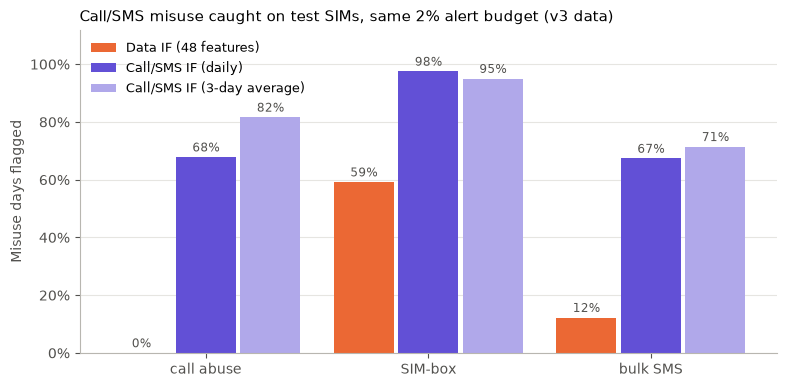

In [6]:
from matplotlib.ticker import PercentFormatter

COLORS = {"Data IF (48 features)": "#eb6834", "Call/SMS IF (daily)": "#6250d6", "Call/SMS IF (3-day average)": "#b0a8ea"}
NAMES = {"call_abuse": "call abuse", "sim_box": "SIM-box", "bulk_sms": "bulk SMS"}
x = np.arange(len(CALL_TYPES))
w = 0.27
fig, ax = plt.subplots(figsize=(9, 4.2))
for k, name in enumerate(COLORS):
    vals = by_type[name].to_numpy()
    bars = ax.bar(x + (k - 1) * (w + 0.02), vals, w, color=COLORS[name], label=name)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in vals], padding=2, fontsize=8.5, color="#52514e")
ax.set_xticks(x, [NAMES[c] for c in CALL_TYPES])
ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("Misuse days flagged")
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.grid(axis="x", visible=False)
ax.set_title("Call/SMS misuse caught on test SIMs, same 2% alert budget (v3 data)", loc="left")
fig.savefig(REPORTS_DIR / "call_sms_detector_experiment.png", dpi=150, bbox_inches="tight")
plt.show()

### Where the false alarms come from
Normal days the call/SMS forest flags, split by the kind of normal SIM (heavy and international callers are legitimate in v3).

In [7]:
name = "Call/SMS IF (daily)"
fa = flags[name] & normal
Xt = Xc.iloc[test_idx]
sim_calls = Xc.loc[y == "normal"].groupby(df.loc[y == "normal", "sim_id"])["calls"].mean()
heavy = set(sim_calls[sim_calls >= sim_calls.quantile(0.95)].index)
intl = set(df.loc[(Xc["intl_call_share"].to_numpy() > 0) & (y == "normal"), "sim_id"])
kind = np.where(np.isin(sims_t, list(heavy)), "heavy caller (top 5% by calls)",
                np.where(np.isin(sims_t, list(intl)), "calls abroad sometimes", "other"))
pd.DataFrame({"normal test days": pd.Series(kind[normal]).value_counts(),
              "flagged": pd.Series(kind[fa]).value_counts()}).fillna(0).astype(int).assign(
    **{"flagged per 1,000": lambda t: (1000 * t["flagged"] / t["normal test days"]).round(1)})

,normal test days,flagged,"flagged per 1,000"
other,18320,180,9.8
calls abroad sometimes,1899,79,41.6
heavy caller (top 5% by calls),851,76,89.3


### Used together: data IF + call/SMS IF
If both run side by side, a day is flagged when either flags it.

In [8]:
both = flags["Data IF (48 features)"] | flags["Call/SMS IF (daily)"]
d = flags["Data IF (48 features)"]
pd.DataFrame({
    "Data IF alone": {"call/SMS misuse days caught": d[is_call].mean(), "data-misuse days flagged": d[is_data].mean(),
                      "false alarms per 1,000 normal days": 1000 * d[normal].mean()},
    "Data IF + call/SMS IF": {"call/SMS misuse days caught": both[is_call].mean(), "data-misuse days flagged": both[is_data].mean(),
                              "false alarms per 1,000 normal days": 1000 * both[normal].mean()},
}).round(3)

,Data IF alone,Data IF + call/SMS IF
call/SMS misuse days caught,0.301,0.816
data-misuse days flagged,0.268,0.272
"false alarms per 1,000 normal days",4.556,19.934


## 5. Findings and decision

**The dedicated call/SMS Isolation Forest is still clearly better than the data forest on call and SMS misuse**, now on misuse generated with realistic normal calling (test SIMs, same 2% alert budget):

| Detector | Call/SMS misuse days caught | First 2 days of an episode caught | False alarms per 1,000 normal days | PR-AUC (call/SMS misuse vs normal) |
|---|---|---|---|---|
| Data IF (48 features) | 30% | 6% | 4.6 | 0.20 |
| **Call/SMS IF (daily)** | **82%** | **88%** | 15.9 | 0.67 |
| Call/SMS IF (3-day average) | 86% | 59% | 14.7 | **0.76** |

**By type** (days caught, daily version): SIM-box 98%, call abuse 68%, bulk SMS 67%. Every call-abuse and bulk-SMS test SIM, and 8 of 9 SIM-box SIMs, is caught on at least one day. The data forest catches no call abuse at all (its data use does not change) and only part of SIM-box (59%, through its collapsing data and jump in sessions).

**What changed from the v2 experiment:**
- **False alarms are ten times higher** (15.9 vs 1.5 per 1,000 normal days). In v2 every normal SIM called the same way, so any change stood out. In v3 normal calling is realistic, and the false alarms come mostly from legitimate unusual callers: heavy callers (top 5% by calls) are flagged on 89 of every 1,000 normal days, SIMs that sometimes call abroad on 42, all other SIMs on 10.
- **Daily vs 3-day average is now a real trade-off.** The 3-day average ranks better overall (PR-AUC 0.76 vs 0.67) and catches slightly more misuse days, but it reacts later: it flags 59% of episodes' first two days against 88% for daily scoring.
- Normal calling now overlaps misuse more: the busiest 1% of normal days reach 13 calls, 26 call minutes and 11 SMS, so mild call abuse and small bulk-SMS bursts look like busy normal days.

**Used together with the data forest**, call/SMS misuse caught rises from 30% to 82%, data-misuse detection is unchanged (26.8% → 27.2%), and false alarms rise from 4.6 to 19.9 per 1,000 normal days.

**Caveats for the write-up:**
- The misuse patterns were designed by us in the generator, so these are results on *these* patterns, not real-world performance.
- The test set holds only 7-10 SIMs per call type, so per-type figures are rough.

**Decision:** keep the dedicated call/SMS Isolation Forest as the third model with its own alert type ("unusual calling/SMS"). It needs no labels, so it works from day one. Two settings are open:
1. **Daily at 2%** (current): fastest to react, but in the combined design most of its extra alerts are false (notebook 01, section 7.4).
2. **3-day average at 1%** (notebook 01's recommendation): about a quarter of the extra false alarms and four times the hit rate, at the cost of reacting a day or two later.

The main remaining improvement is to reduce false alarms on legitimate heavy and international callers, for example by giving the forest more features relative to each SIM's own past (it has only 6 of 20 now).